# RuangRasa: Prediksi Risiko Gangguan Depresi Mayor (CDC NHANES)
**Notebook Lengkap End-to-End (1 File Terpadu)**

Notebook ini menggabungkan seluruh alur proyek *Machine Learning* dari awal hingga akhir dalam satu file:
1. **Persiapan Data & Pembagian 80:20 Berstrata**
2. **Eksplorasi Data (EDA) & 6 Visualisasi**
3. **Preprocessing Bebas Kebocoran Data (*Zero Data Leakage*)**
4. **Pelatihan, Tuning (*5-Fold Stratified CV*), dan Komparasi 3 Model**
5. **Evaluasi Data Uji (*Holdout*), *Confusion Matrix*, Interpretasi Fitur, & Ekspor Model**

> **Catatan:** Proyek ini ditujukan untuk edukasi dan skrining awal risiko depresi (berbasis skor PHQ-9 ≥ 10 pada data CDC NHANES 2005–2018), **bukan alat diagnosis medis resmi**.

## 1. Inisialisasi Lingkungan, Path Proyek, dan Kontrak Fitur

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
from datetime import datetime, timezone

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Deteksi otomatis root proyek (berfungsi dari Source_Code/notebooks maupun Model/ipynb model)
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Dataset/Data_Asli/nhanes_depression_raw.csv").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari dalam folder proyek RuangRasa yang lengkap dengan folder Dataset.")

SEED = 42
TARGET = "Depression"
LABELS = ["Not Depressed", "Depressed"]

CATEGORICAL = [
    "Gender", "Education Level", "Marital Status", "Household Income",
    "Trouble Sleeping History", "Vigorous Recreation", "Moderate Recreation",
    "Current Smoker", "Memory Problems", "Cant Work", "Limited Work",
]
NUMERIC = ["Age", "Sleep Hours", "Sedentary Time", "BMI", "Systolic", "Diastolic", "Pulse"]
FEATURES = CATEGORICAL + NUMERIC

REPORTS = ROOT / "Source_Code/reports"
EDA = REPORTS / "eda"
MODELING = REPORTS / "modeling"
ANALYSIS = REPORTS / "analysis"
PROCESSED = ROOT / "Dataset/Data_Olahan"
MODELS = ROOT / "Model"
MODELS_JOBLIB = MODELS / "joblib untuk streamlit"

for folder in [EDA, MODELING, ANALYSIS, PROCESSED, MODELS, MODELS_JOBLIB]:
    folder.mkdir(parents=True, exist_ok=True)


def prepare_features(frame):
    data = frame.copy()
    missing = sorted(set(FEATURES) - set(data.columns))
    if missing:
        raise ValueError("Kolom wajib belum tersedia: " + ", ".join(missing))
    data = data[FEATURES].copy()
    for col in CATEGORICAL:
        data[col] = data[col].astype(str).replace(r"^\s*$", np.nan, regex=True)
    for col in NUMERIC:
        original = data[col]
        data[col] = pd.to_numeric(original, errors="coerce")
        invalid = original.notna() & original.astype(str).str.strip().ne("") & data[col].isna()
        if invalid.any():
            raise ValueError(f"Kolom {col} berisi nilai non-numerik.")
        if np.isinf(data[col].to_numpy(dtype=float)).any():
            raise ValueError(f"Kolom {col} berisi nilai infinity.")
    return data


def make_preprocessor():
    num_pipeline = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat_pipeline = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("numeric", num_pipeline, NUMERIC), ("categorical", cat_pipeline, CATEGORICAL)])


def save_json(path, value):
    path.write_text(
        json.dumps(value, indent=2, ensure_ascii=False, default=lambda x: x.item() if isinstance(x, np.generic) else str(x)),
        encoding="utf-8",
    )


def save_figure(path):
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    display(Image(filename=str(path)))
    plt.close()


def eval_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
    }


print("Root proyek:", ROOT)
print(f"Total fitur: {len(FEATURES)} ({len(CATEGORICAL)} kategorikal, {len(NUMERIC)} numerik)")

Root proyek: D:\KULIAH\sem-5\MACHINE LEARNING\PJBL\RuangRasa
Total fitur: 18 (11 kategorikal, 7 numerik)


## 2. Persiapan Data, Pemeriksaan Duplikat, dan Pembagian 80:20 Berstrata

In [2]:
source = ROOT / "Dataset/Data_Asli/nhanes_depression_raw.csv"
raw = pd.read_csv(source, low_memory=False)
if set(raw[TARGET].unique()) != set(LABELS):
    raise ValueError("Label dataset tidak sesuai kontrak.")

features_all = prepare_features(raw)
canonical = features_all.assign(**{TARGET: raw[TARGET]})
duplicate_mask = canonical.duplicated(keep="first")
raw.loc[duplicate_mask].to_csv(EDA / "duplicate_records.csv", index=False)

clean = canonical.loc[~duplicate_mask].copy().reset_index(drop=True)
ids = raw.loc[~duplicate_mask, "SEQN"].reset_index(drop=True)

profile_hashes = pd.util.hash_pandas_object(clean[FEATURES], index=False).astype(str)
conflict_counts = clean.assign(profile_hash=profile_hashes).groupby("profile_hash")[TARGET].nunique()
conflict_hashes = set(conflict_counts[conflict_counts > 1].index)
clean.assign(profile_hash=profile_hashes).loc[profile_hashes.isin(conflict_hashes)].to_csv(
    EDA / "conflicting_profiles.csv", index=False
)
clean.assign(source_seqn=ids, profile_hash=profile_hashes).to_csv(PROCESSED / "cleaned.csv", index=False)

X = clean[FEATURES]
y = clean[TARGET]

# Pembagian data latih 80% dan uji 20% secara berstrata (sebelum transformasi apa pun)
X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split(
    X, y, clean.index, test_size=0.20, stratify=y, random_state=SEED
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
fold_records = []
for fold, (fit_idx, val_idx) in enumerate(cv.split(X_train, y_train), 1):
    for role, indexes in [("fit", fit_idx), ("validation", val_idx)]:
        for pos in indexes:
            fold_records.append({"fold": fold, "role": role, "clean_index": int(X_train.index[pos]), "label": y_train.iloc[pos]})
pd.DataFrame(fold_records).to_csv(MODELING / "cv_folds.csv", index=False)

for name, indices in [("train", train_idx), ("test", test_idx)]:
    clean.loc[indices].assign(source_seqn=ids.loc[indices]).to_csv(PROCESSED / f"{name}.csv", index=False)

print(f"Data asli    : {raw.shape[0]:,} baris x {raw.shape[1]} kolom")
print(f"Duplikat     : {int(duplicate_mask.sum())} | Konflik profil: {len(conflict_hashes)}")
print(f"Data latih   : {len(X_train):,} baris (80%)")
print(f"Data uji     : {len(X_test):,} baris (20%)")
display(pd.DataFrame({"Data Latih": y_train.value_counts(), "Data Uji": y_test.value_counts()}).reindex(LABELS))

Data asli    : 36,259 baris x 20 kolom
Duplikat     : 0 | Konflik profil: 0
Data latih   : 29,007 baris (80%)
Data uji     : 7,252 baris (20%)


,Data Latih,Data Uji
Depression,,
Not Depressed,26473,6618
Depressed,2534,634


## 3. Eksplorasi Data (EDA) & 6 Visualisasi Utama

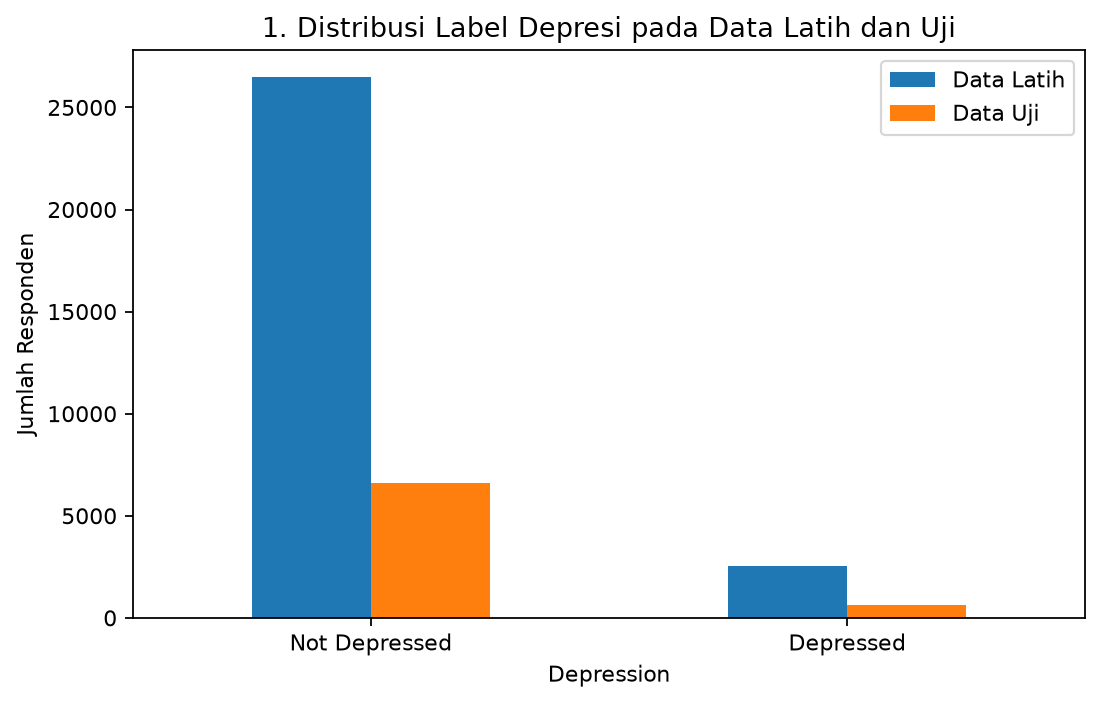

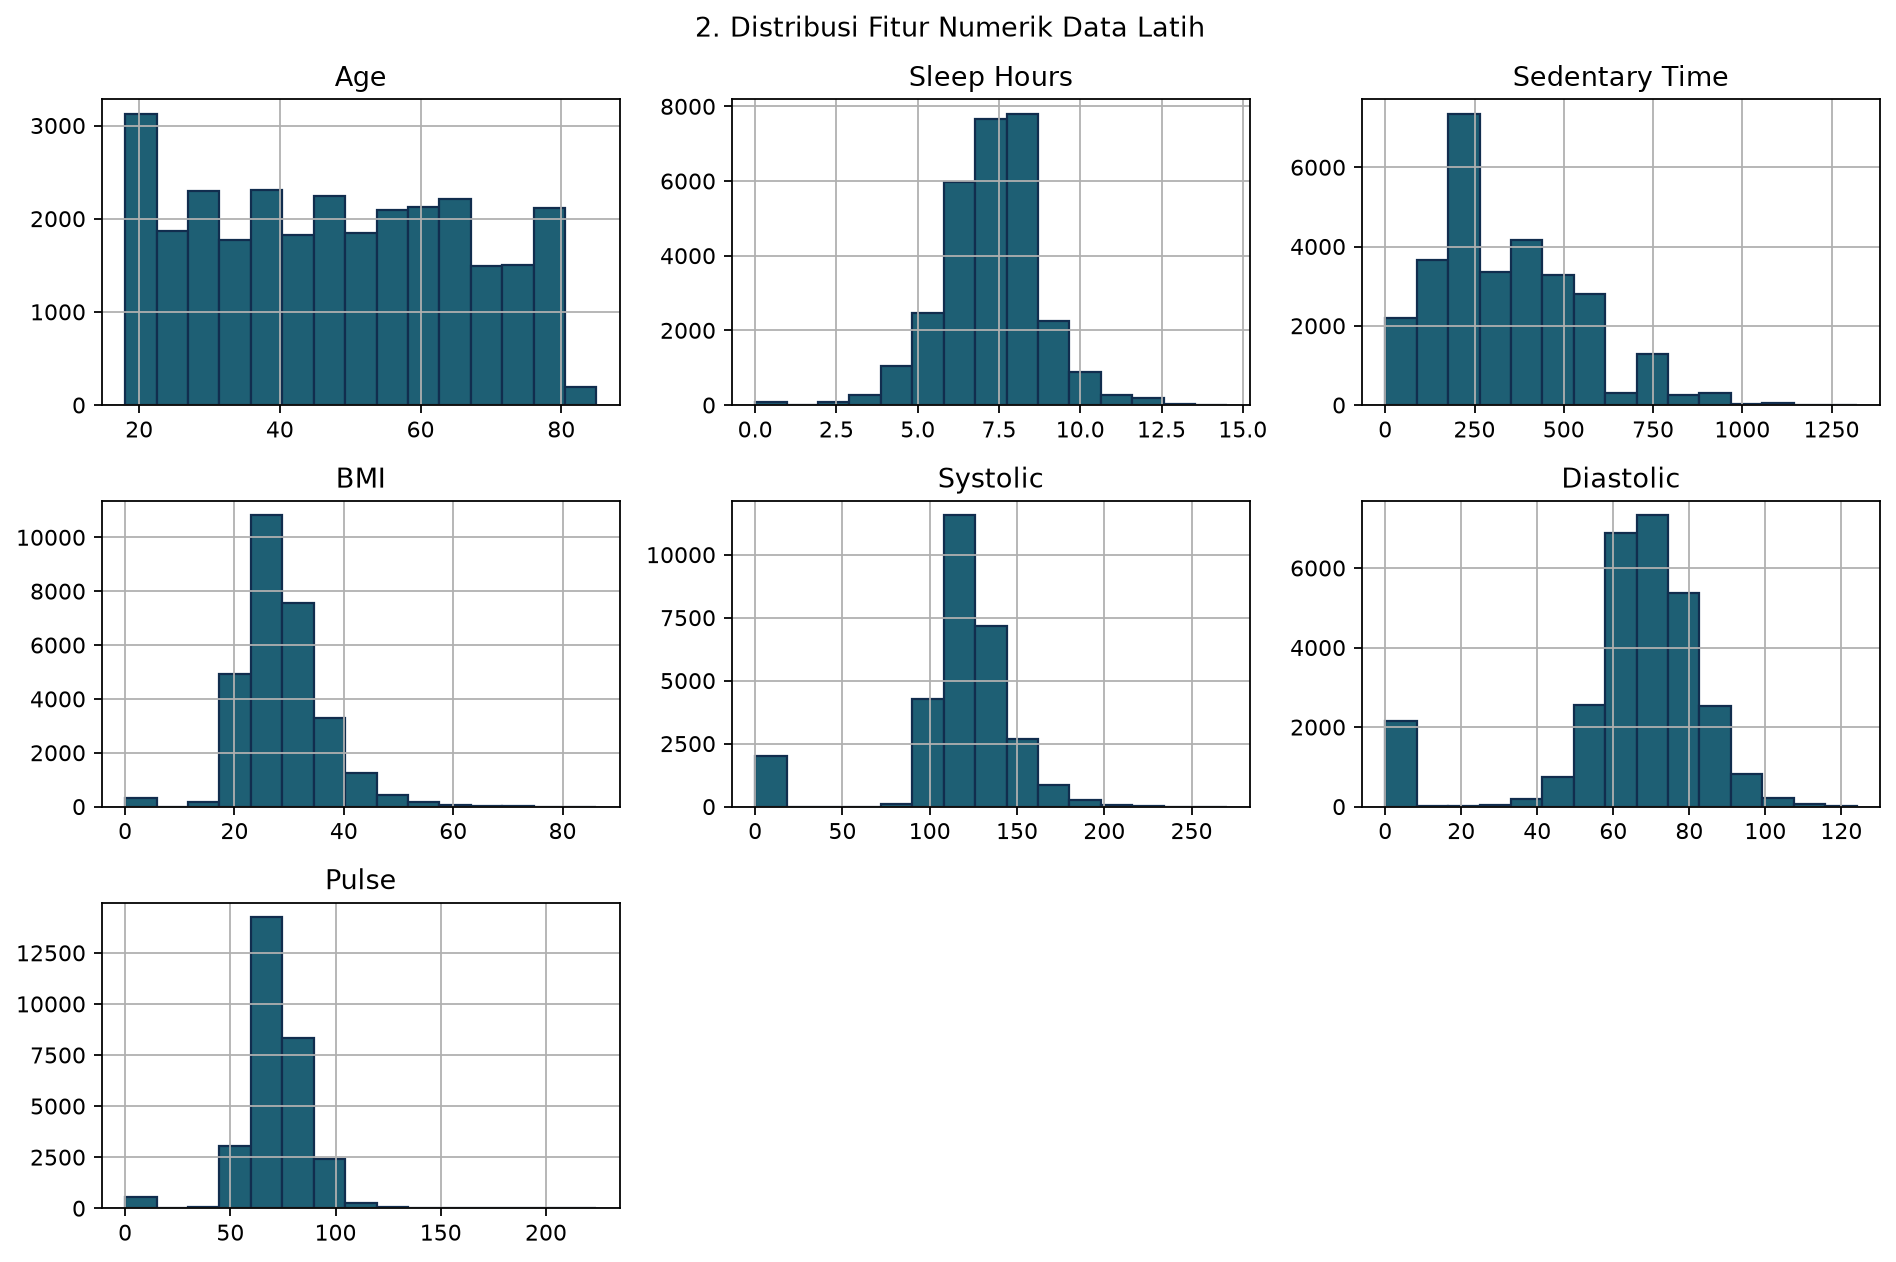

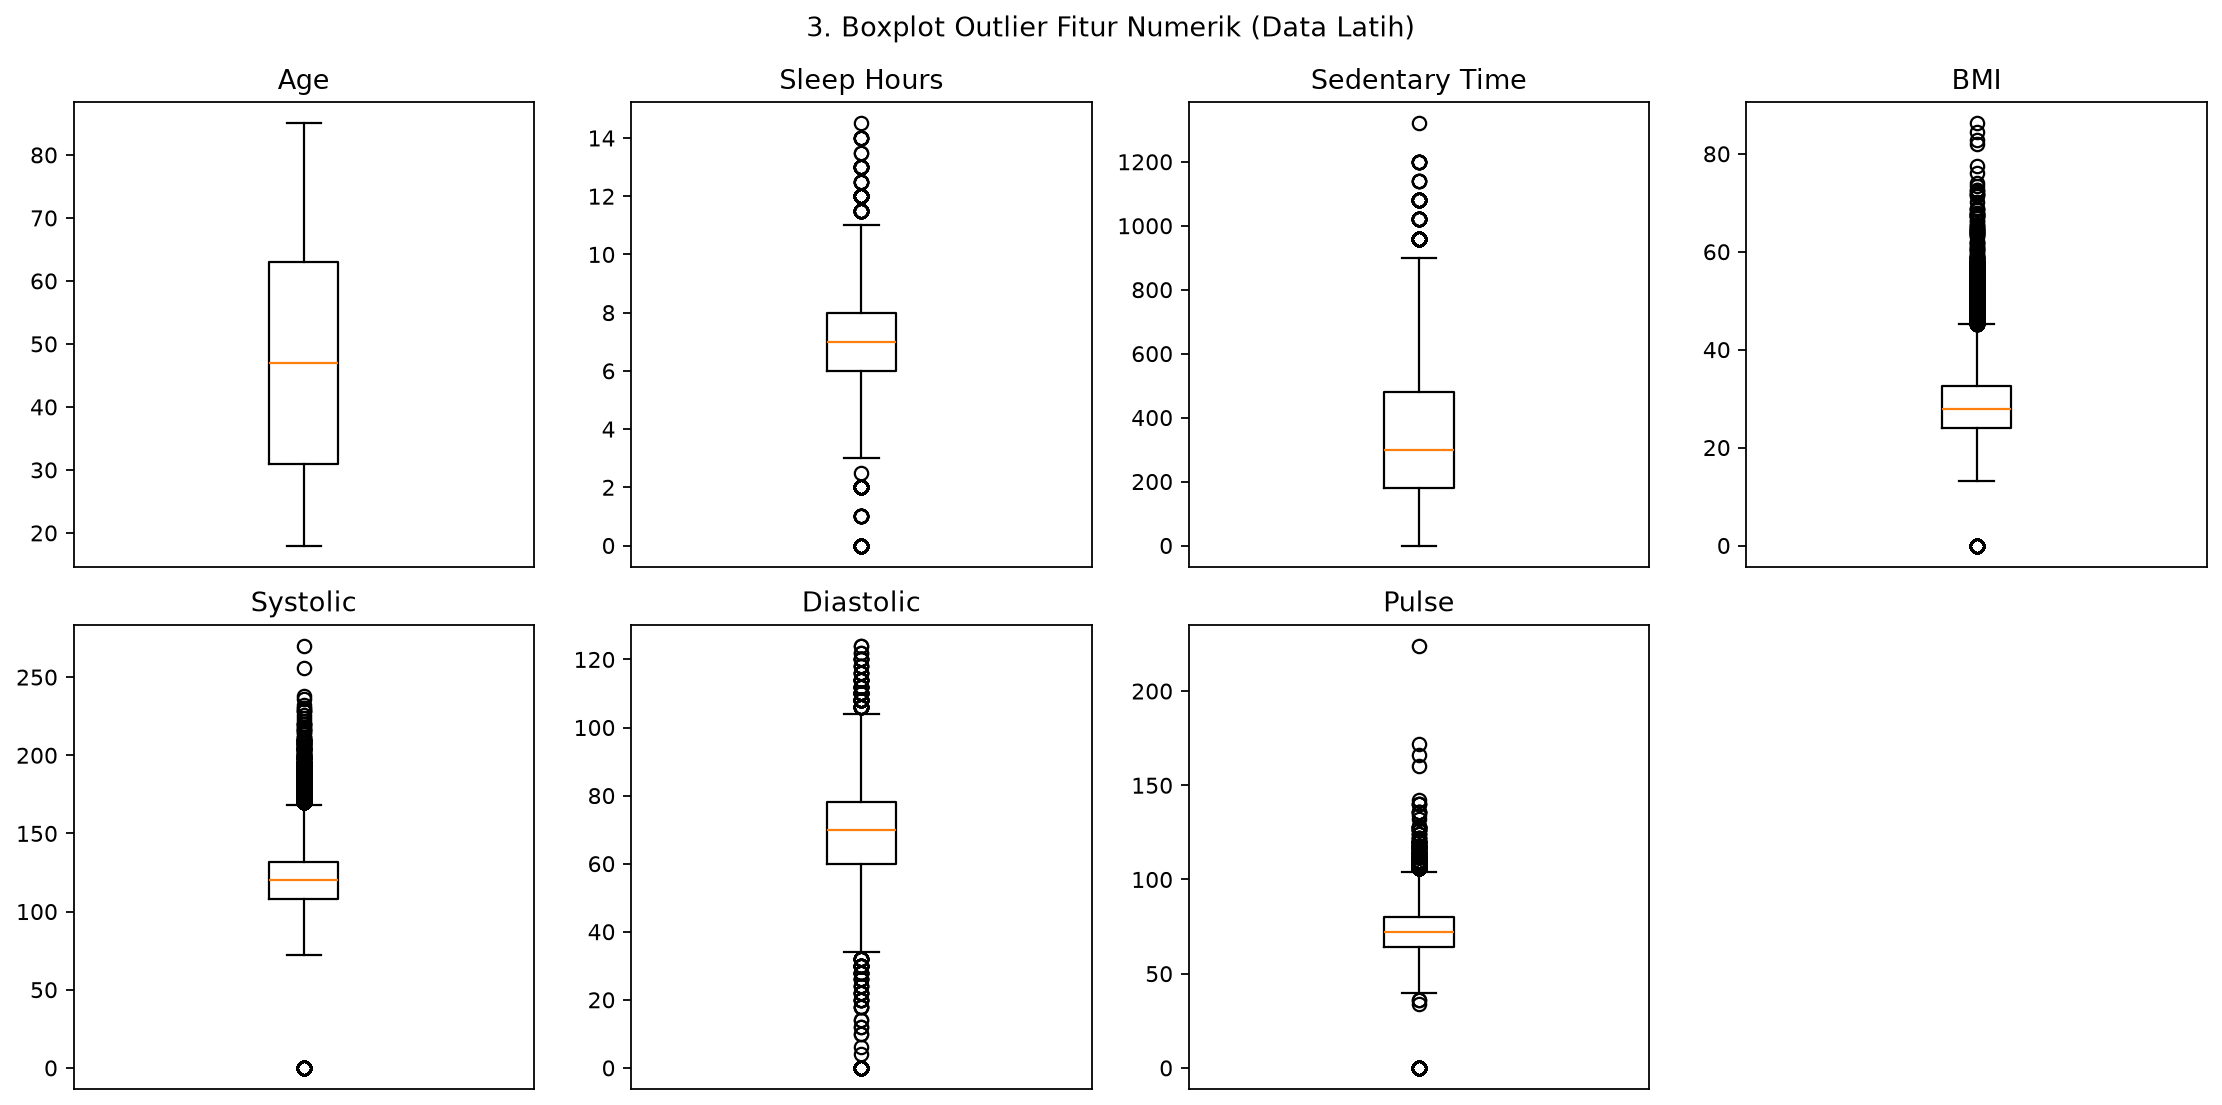

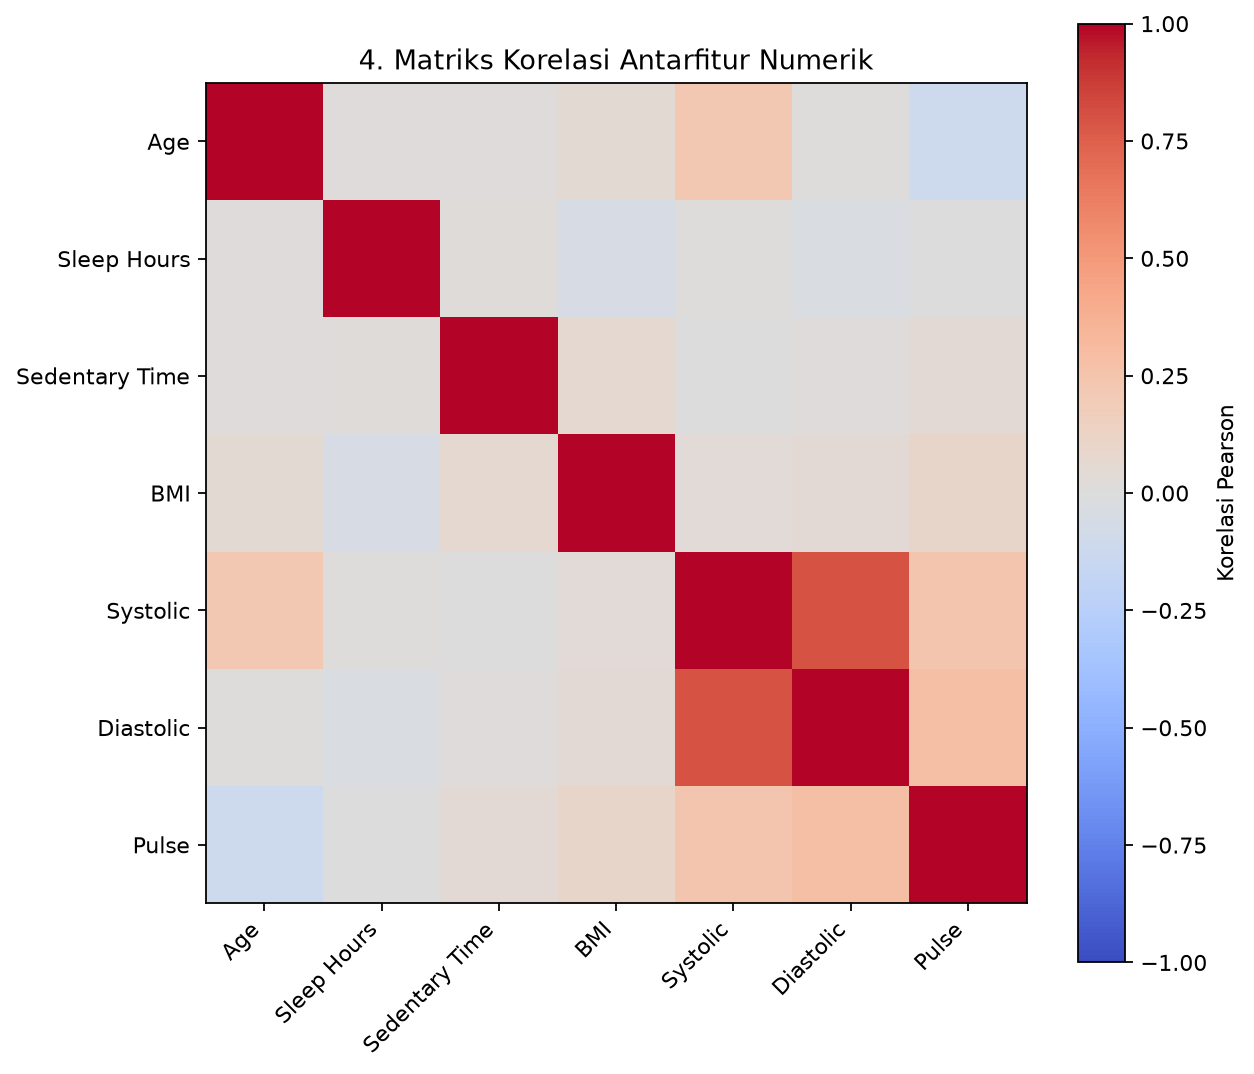

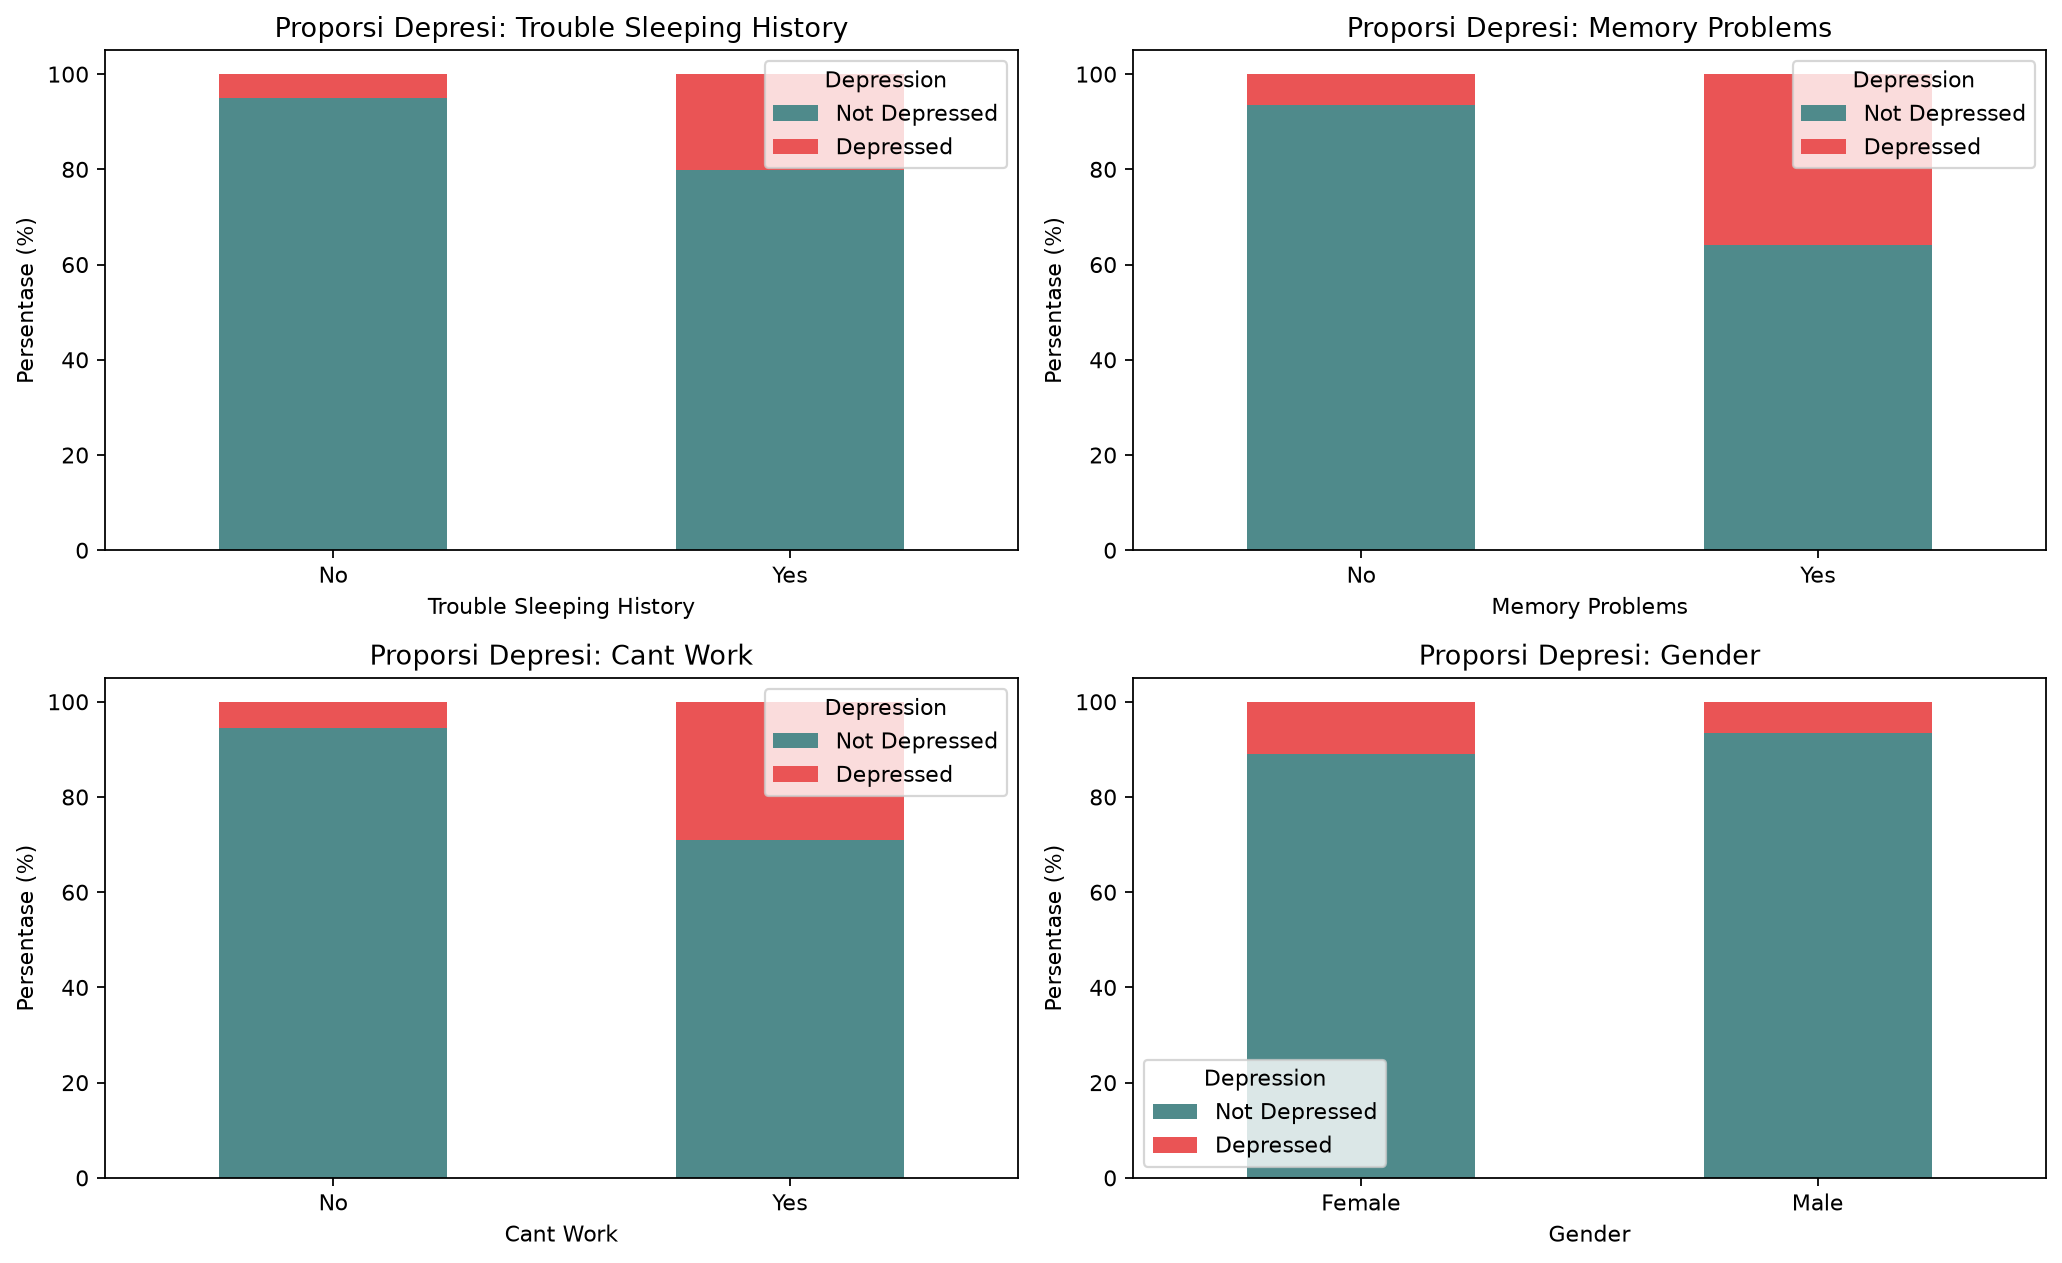

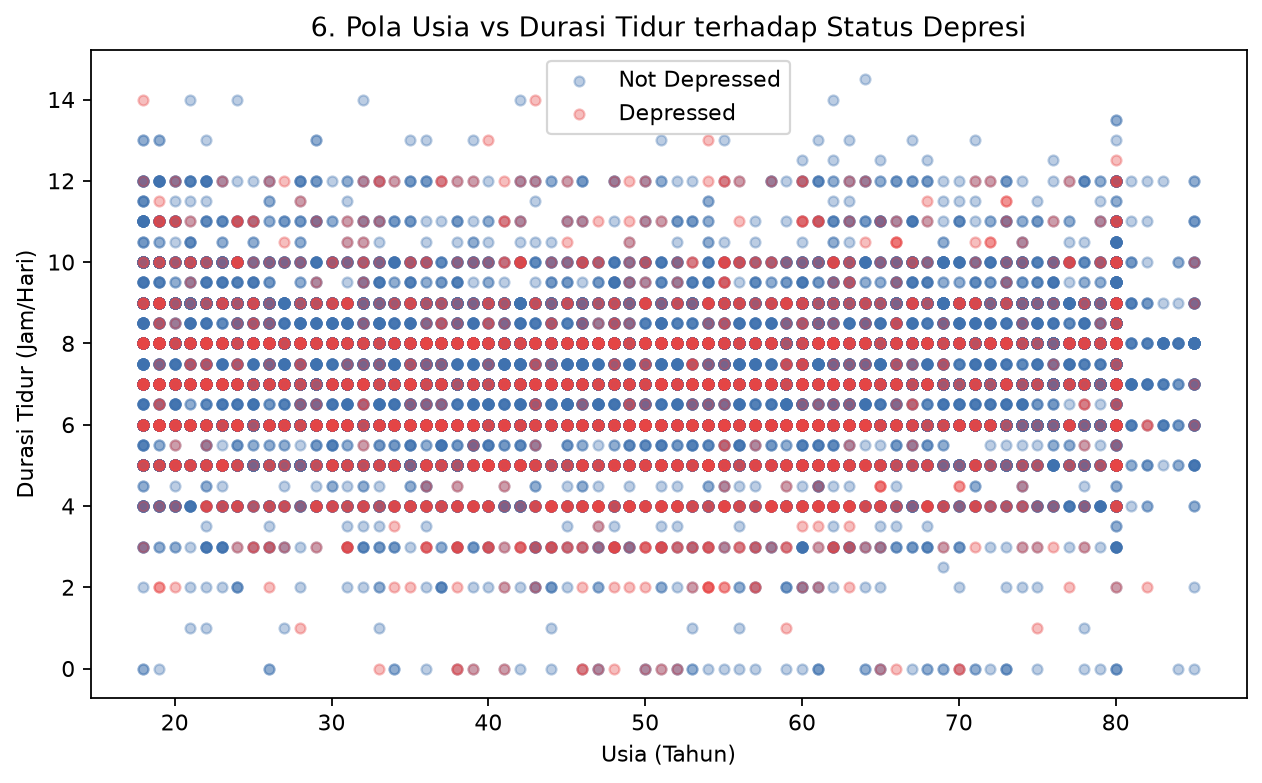

In [3]:
# Simpan ringkasan kualitas data, statistik deskriptif, dan deteksi outlier IQR pada data latih
raw.describe(include="all").to_csv(EDA / "descriptive_raw.csv")
clean.describe(include="all").to_csv(EDA / "descriptive_cleaned.csv")

quality = pd.DataFrame([
    {"feature": c, "dtype": str(raw[c].dtype), "missing_count": int(raw[c].isna().sum()), "unique_count": int(raw[c].nunique())}
    for c in raw.columns
])
quality.to_csv(EDA / "data_quality.csv", index=False)

outliers = []
for col in NUMERIC:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers.append({"feature": col, "lower_iqr": low, "upper_iqr": high, "outlier_count_train": int(((X_train[col] < low) | (X_train[col] > high)).sum())})
outliers_df = pd.DataFrame(outliers)
outliers_df.to_csv(EDA / "outliers_train.csv", index=False)

summary = {
    "raw_rows": len(raw),
    "raw_columns": len(raw.columns),
    "model_features": len(FEATURES),
    "duplicates_removed": int(duplicate_mask.sum()),
    "clean_rows": len(clean),
    "unique_profiles": int(profile_hashes.nunique()),
    "conflicting_profiles": len(conflict_hashes),
    "train_rows": len(train_idx),
    "test_rows": len(test_idx),
    "seed": SEED,
    "selection_metric": "Stratified 5-Fold Training CV Macro-F1",
    "split_ratio": "80% Train : 20% Test Stratified",
    "class_counts_raw": raw[TARGET].value_counts().to_dict(),
    "class_counts_train": y_train.value_counts().to_dict(),
    "class_counts_test": y_test.value_counts().to_dict(),
}
save_json(EDA / "summary.json", summary)

# 1. Distribusi Kelas
plt.figure(figsize=(7, 4.5))
pd.DataFrame({"Data Latih": y_train.value_counts(), "Data Uji": y_test.value_counts()}).reindex(LABELS).plot.bar(ax=plt.gca(), rot=0)
plt.ylabel("Jumlah Responden")
plt.title("1. Distribusi Label Depresi pada Data Latih dan Uji")
save_figure(EDA / "01_distribusi_kelas.png")

# 2. Histogram Fitur Numerik
X_train[NUMERIC].hist(figsize=(12, 8), bins=15, color="#1e5f74", edgecolor="#112d4e")
plt.suptitle("2. Distribusi Fitur Numerik Data Latih")
save_figure(EDA / "02_histogram_train.png")

# 3. Boxplot Outlier
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, col in zip(axes.flat, NUMERIC):
    ax.boxplot(X_train[col].dropna())
    ax.set_title(col)
    ax.set_xticks([])
for ax in axes.flat[len(NUMERIC):]:
    ax.axis("off")
plt.suptitle("3. Boxplot Outlier Fitur Numerik (Data Latih)")
save_figure(EDA / "03_boxplot_train.png")

# 4. Matriks Korelasi
correlation = X_train[NUMERIC].corr()
correlation.to_csv(EDA / "correlation_train.csv")
plt.figure(figsize=(8, 7))
plt.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(NUMERIC)), NUMERIC, rotation=45, ha="right")
plt.yticks(range(len(NUMERIC)), NUMERIC)
plt.colorbar(label="Korelasi Pearson")
plt.title("4. Matriks Korelasi Antarfitur Numerik")
save_figure(EDA / "04_korelasi_train.png")

# 5. Proporsi Fitur Kategorikal Kunci
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, ["Trouble Sleeping History", "Memory Problems", "Cant Work", "Gender"]):
    counts = pd.crosstab(X_train[col], y_train, normalize="index") * 100
    counts.reindex(columns=LABELS).plot.bar(stacked=True, ax=ax, rot=0, color=["#4f8a8b", "#ea5455"])
    ax.set_title(f"Proporsi Depresi: {col}")
    ax.set_ylabel("Persentase (%)")
save_figure(EDA / "05_kategorikal_train.png")

# 6. Scatter Plot Usia vs Durasi Tidur
plt.figure(figsize=(8, 5))
for label, color in [("Not Depressed", "#3f72af"), ("Depressed", "#e84545")]:
    sub = X_train.loc[y_train == label]
    plt.scatter(sub["Age"], sub["Sleep Hours"], label=label, alpha=0.35, s=20, c=color)
plt.xlabel("Usia (Tahun)")
plt.ylabel("Durasi Tidur (Jam/Hari)")
plt.title("6. Pola Usia vs Durasi Tidur terhadap Status Depresi")
plt.legend()
save_figure(EDA / "06_scatter_train.png")

## 4. Preprocessing Data (Pipeline Imputasi, StandardScaler, & OneHotEncoder)

In [4]:
pre_preview = make_preprocessor()
X_train_encoded = pre_preview.fit_transform(X_train)
encoded_cols = pre_preview.get_feature_names_out()
preview_df = pd.DataFrame(X_train_encoded[:5], columns=encoded_cols)
preview_df.to_csv(PROCESSED / "preview_preprocessing_train.csv", index=False)

print(f"Dimensi sebelum encoding : {X_train.shape}")
print(f"Dimensi sesudah encoding : {X_train_encoded.shape} (fit hanya pada data latih)")
display(preview_df.iloc[:, :10])

Dimensi sebelum encoding : (29007, 18)
Dimensi sesudah encoding : (29007, 53) (fit hanya pada data latih)


,numeric__Age,numeric__Sleep Hours,numeric__Sedentary Time,numeric__BMI,numeric__Systolic,numeric__Diastolic,numeric__Pulse,categorical__Gender_Female,categorical__Gender_Male,categorical__Education Level_9-11th Grade
0,0.225098,0.586180,-0.748064,-0.389168,0.675952,1.418560,-0.215458,0.0,1.0,0.0
1,0.278382,-1.328249,-1.495760,-0.712880,0.290229,0.960485,-0.727473,0.0,1.0,0.0
2,1.717058,1.224323,-0.149907,1.600669,0.951468,0.227564,-0.599469,1.0,0.0,1.0
3,0.065245,0.586180,1.345486,0.377171,2.769876,1.510175,-1.239488,1.0,0.0,1.0
4,-0.201177,-1.966392,-0.748064,-0.613784,0.731055,1.235330,-0.343462,1.0,0.0,0.0


## 5. Pelatihan, Hyperparameter Tuning, dan Komparasi 3 Model (5-Fold Stratified CV)

In [5]:
definitions = {
    "logistic_regression": (
        LogisticRegression(max_iter=500, random_state=SEED),
        {"model__C": [0.1, 1.0, 10.0], "model__class_weight": ["balanced", None]},
    ),
    "decision_tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"model__max_depth": [4, 6, 8], "model__class_weight": ["balanced", None]},
    ),
    "random_forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {"model__n_estimators": [100], "model__max_depth": [6, 10], "model__class_weight": ["balanced"]},
    ),
}

fitted, rows = {}, []
for name, (model, params) in definitions.items():
    pipeline = Pipeline([("preprocess", make_preprocessor()), ("model", model)])
    baseline = cross_validate(pipeline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    search = GridSearchCV(
        pipeline, params, cv=cv, scoring="f1_macro", n_jobs=-1,
        return_train_score=True, error_score="raise"
    )
    search.fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    table = pd.DataFrame(search.cv_results_)
    table.to_csv(MODELING / f"cv_results_{name}.csv", index=False)
    best_idx = search.best_index_
    rows.append({
        "model": name,
        "baseline_cv_f1": float(np.mean(baseline["test_score"])),
        "cv_f1_mean": float(search.best_score_),
        "cv_f1_std": float(table.loc[best_idx, "std_test_score"]),
        "cv_train_f1": float(table.loc[best_idx, "mean_train_score"]),
        "best_params": json.dumps(search.best_params_),
    })
    joblib.dump(search.best_estimator_, MODELS_JOBLIB / f"{name}_pipeline.joblib")
    print(f"{name:20s} -> CV Macro-F1: {search.best_score_:.4f} ± {table.loc[best_idx, 'std_test_score']:.4f} | Params: {search.best_params_}")

# Kunci model terpilih HANYA dari skor CV data latih
selection = max(rows, key=lambda r: r["cv_f1_mean"])["model"]
print("\nModel Terpilih Berdasarkan CV Data Latih:", selection)

logistic_regression  -> CV Macro-F1: 0.6216 ± 0.0037 | Params: {'model__C': 1.0, 'model__class_weight': None}


decision_tree        -> CV Macro-F1: 0.6299 ± 0.0140 | Params: {'model__class_weight': None, 'model__max_depth': 6}


random_forest        -> CV Macro-F1: 0.6428 ± 0.0074 | Params: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__n_estimators': 100}

Model Terpilih Berdasarkan CV Data Latih: random_forest


## 6. Evaluasi Holdout Test Set, Confusion Matrix, Interpretasi Fitur, & Ekspor

Dummy Majority Baseline (Test): {'accuracy': 0.9126, 'precision_macro': 0.4563, 'recall_macro': 0.5, 'f1_macro': 0.4771}


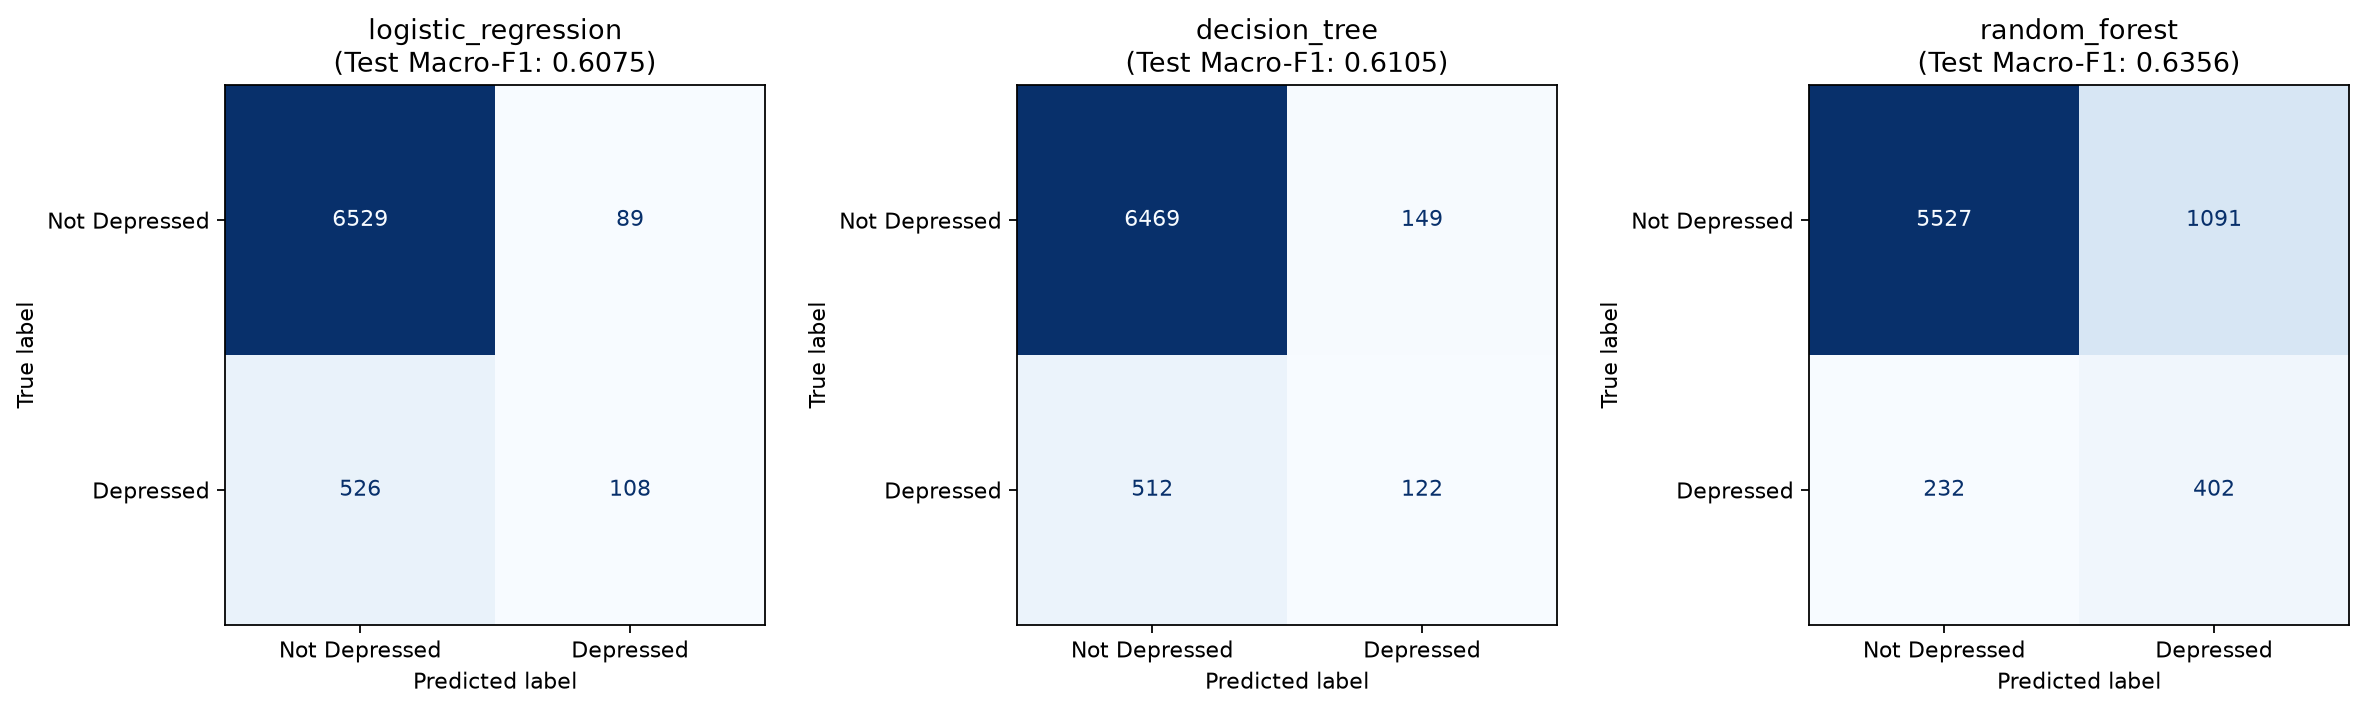

,model,cv_f1_mean,cv_f1_std,train_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,selected_by_cv
0,logistic_regression,0.621636,0.003684,0.621940,0.915196,0.736833,0.578449,0.607474,False
1,decision_tree,0.629851,0.013954,0.657171,0.908853,0.688421,0.584957,0.610503,False
2,random_forest,0.642809,0.007402,0.699875,0.817568,0.614486,0.734608,0.635553,True


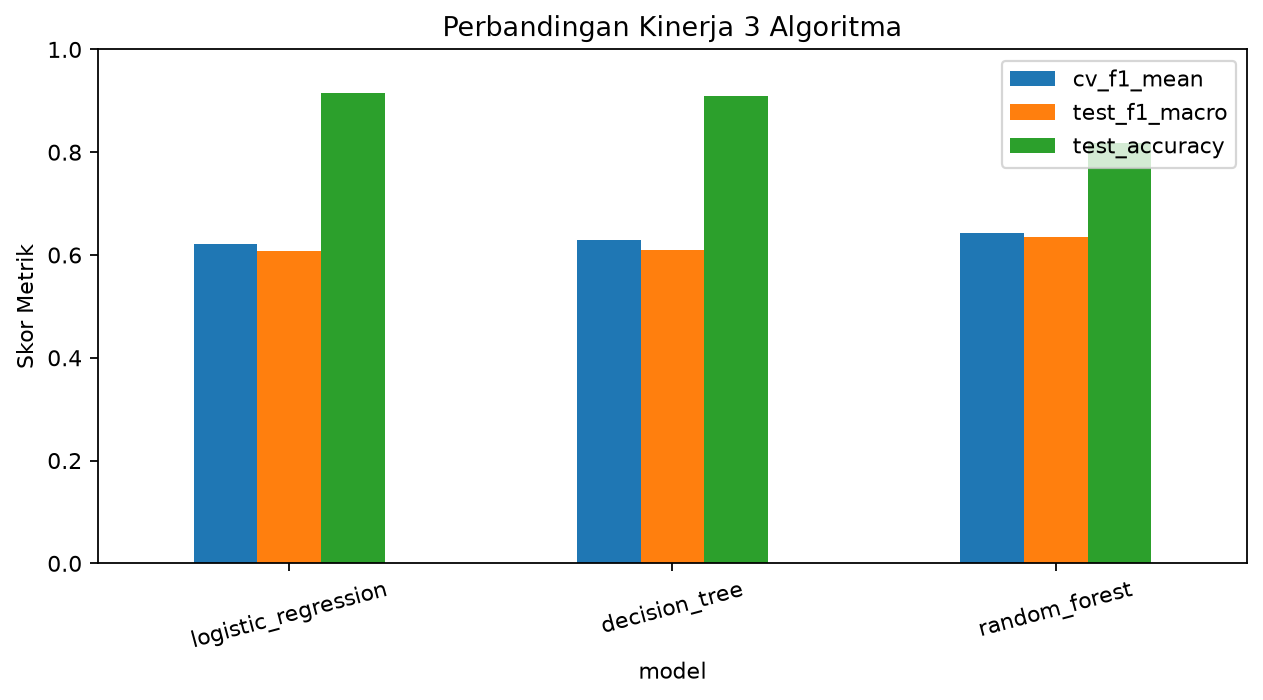

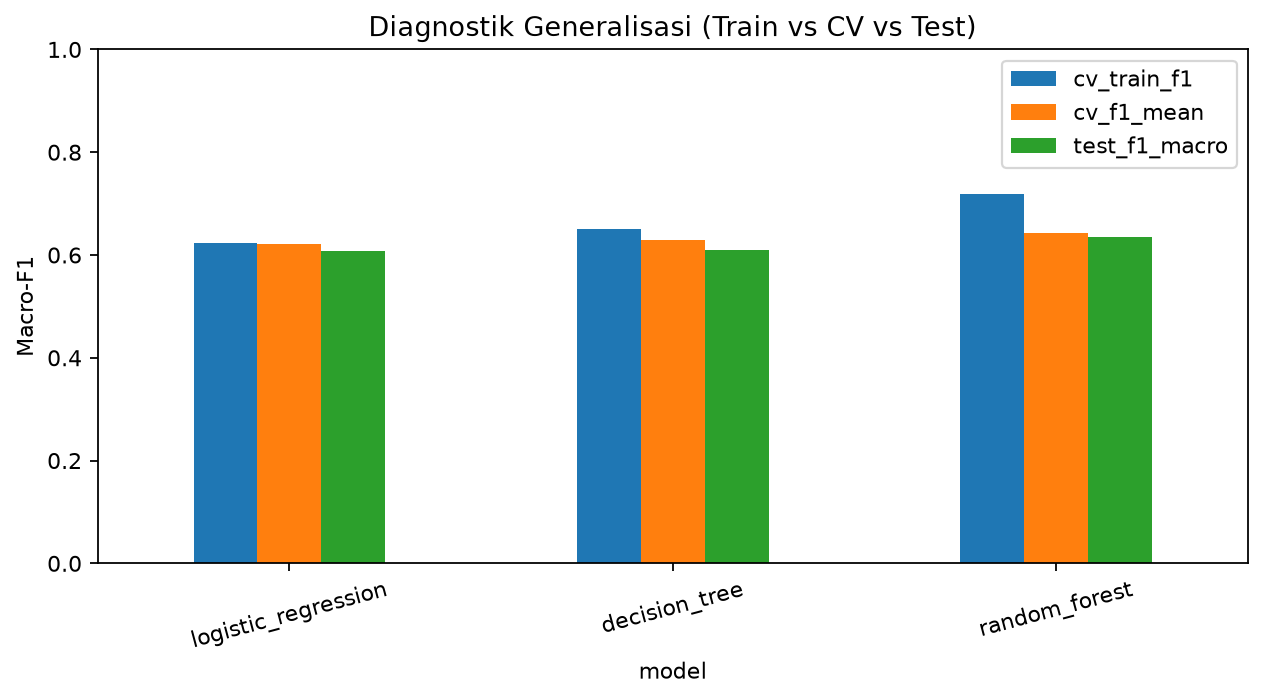

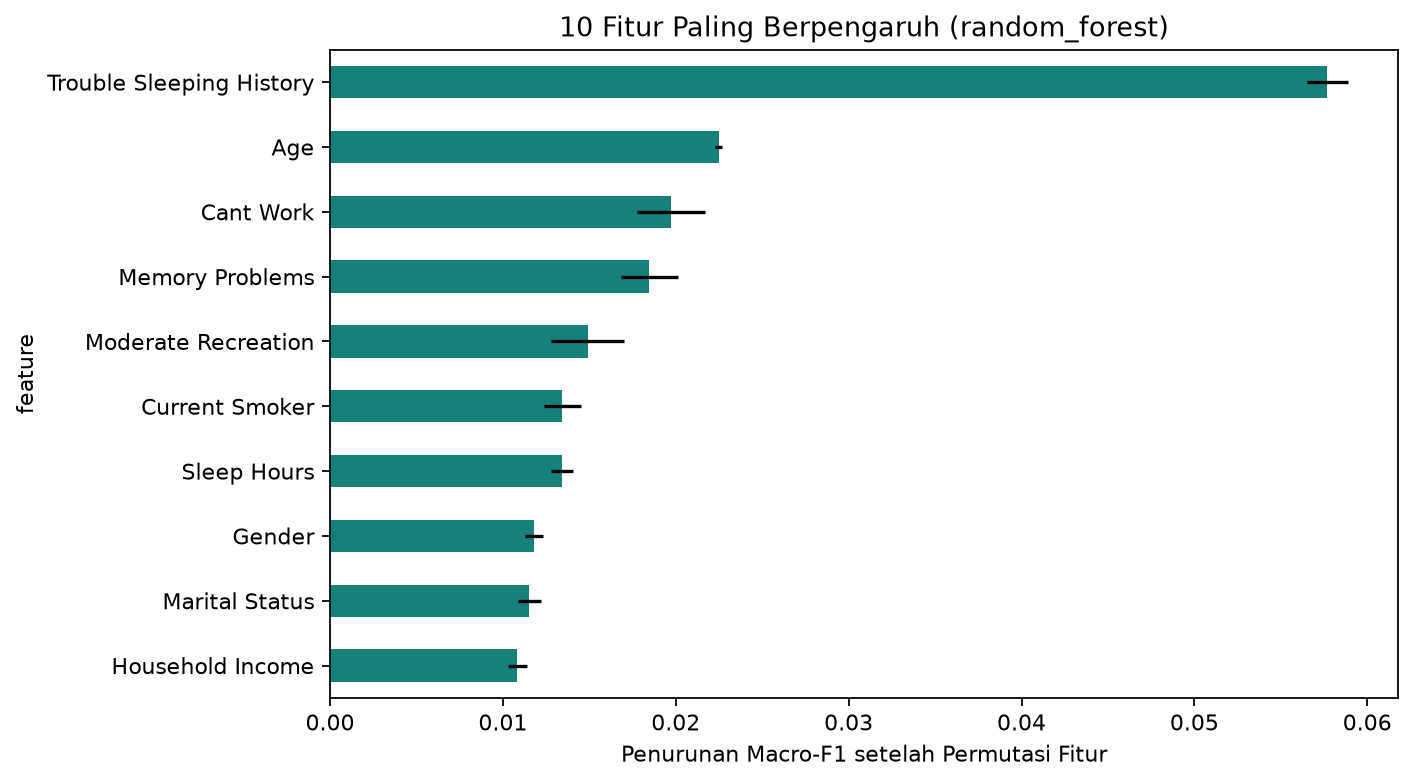

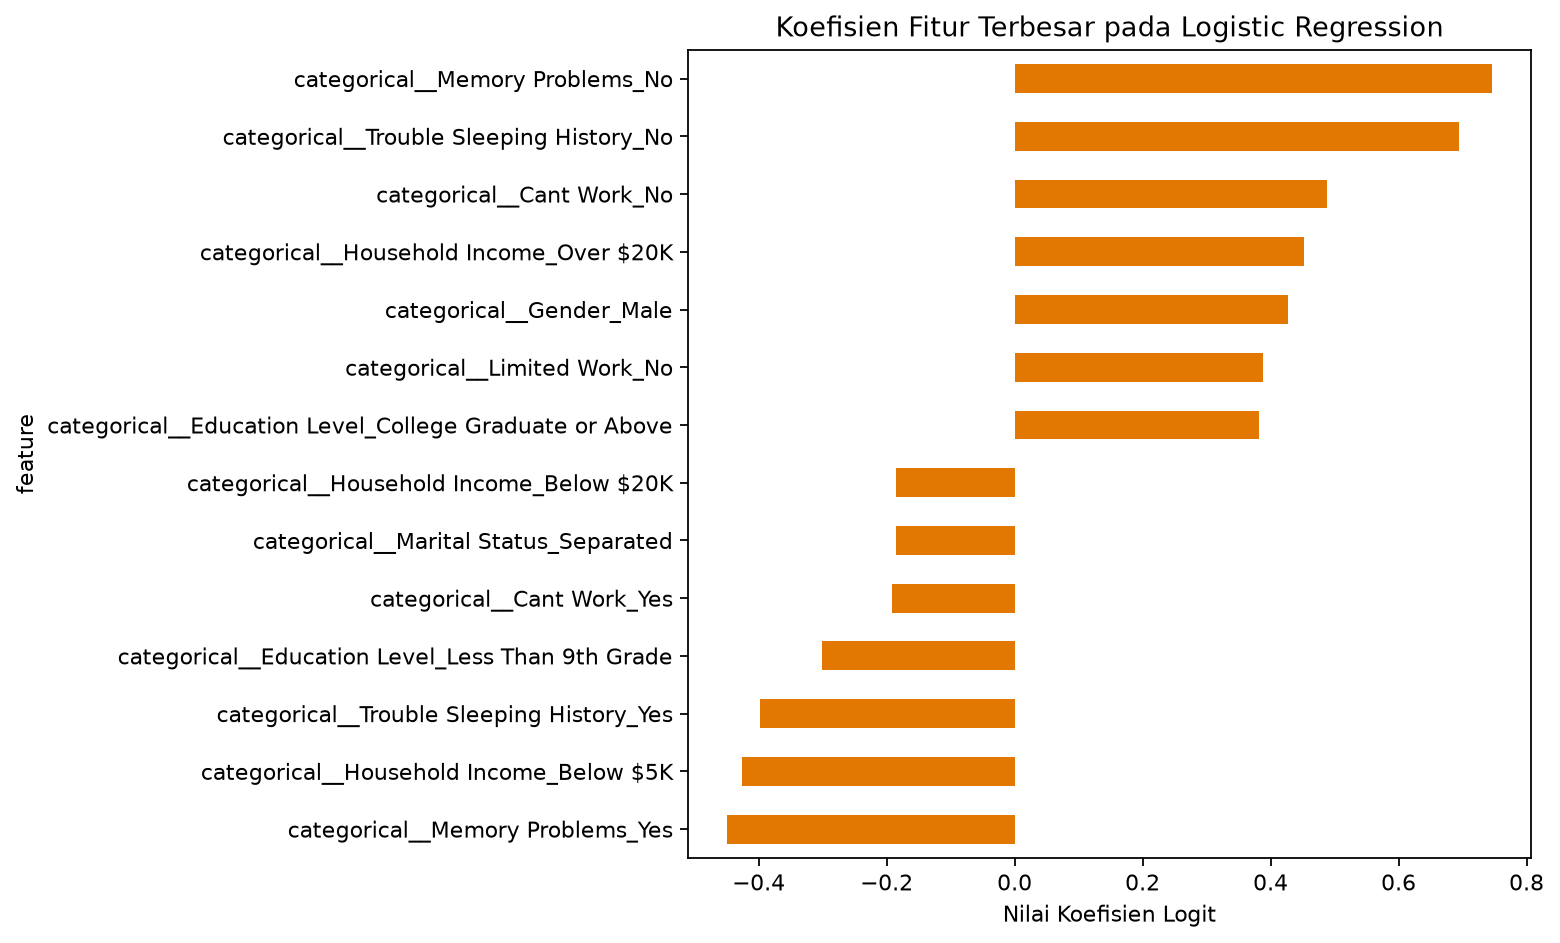

,Gender,Age,Sleep Hours,Trouble Sleeping History,Prediksi,Prob_Depressed
0,Female,19,8.0,No,Not Depressed,0.6068
1,Male,53,7.0,No,Not Depressed,0.9004
2,Male,39,5.0,Yes,Depressed,0.4171
3,Female,28,6.0,No,Not Depressed,0.5044
4,Female,63,6.0,No,Not Depressed,0.8408


In [6]:
dummy = Pipeline([("preprocess", make_preprocessor()), ("model", DummyClassifier(strategy="most_frequent"))])
dummy.fit(X_train, y_train)
dummy_scores = eval_metrics(y_test, dummy.predict(X_test))
save_json(MODELING / "dummy_baseline.json", dummy_scores)
print("Dummy Majority Baseline (Test):", {k: round(v, 4) for k, v in dummy_scores.items()})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, row in zip(axes, rows):
    name = row["model"]
    estimator = fitted[name]
    pred_test = estimator.predict(X_test)
    pred_train = estimator.predict(X_train)

    row.update({"train_" + k: v for k, v in eval_metrics(y_train, pred_train).items()})
    row.update({"test_" + k: v for k, v in eval_metrics(y_test, pred_test).items()})
    row["selected_by_cv"] = (name == selection)
    row["train_cv_gap"] = float(row["cv_train_f1"] - row["cv_f1_mean"])

    save_json(
        MODELING / f"classification_report_{name}.json",
        classification_report(y_test, pred_test, labels=LABELS, output_dict=True, zero_division=0),
    )

    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred_test, labels=LABELS), display_labels=LABELS
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\n(Test Macro-F1: {row['test_f1_macro']:.4f})")

    probs = estimator.predict_proba(X_test)
    records = X_test.copy().assign(
        clean_index=X_test.index, actual=y_test, predicted=pred_test, correct=(y_test.to_numpy() == pred_test)
    )
    for j, label in enumerate(estimator.classes_):
        records[f"probability_{label}"] = probs[:, j]
    records.to_csv(MODELING / f"predictions_{name}.csv", index=False)
    records.loc[~records.correct].to_csv(MODELING / f"errors_{name}.csv", index=False)

save_figure(MODELING / "01_confusion_matrices.png")

results = pd.DataFrame(rows)
results.to_csv(MODELING / "model_comparison.csv", index=False)
results.to_csv(MODELS / "ringkasan_perbandingan_model.csv", index=False)
display(results[["model", "cv_f1_mean", "cv_f1_std", "train_f1_macro", "test_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro", "selected_by_cv"]])

# Grafik Perbandingan Model & Generalisasi
results.set_index("model")[["cv_f1_mean", "test_f1_macro", "test_accuracy"]].plot.bar(figsize=(8, 4.5), ylim=(0, 1), rot=15)
plt.ylabel("Skor Metrik")
plt.title("Perbandingan Kinerja 3 Algoritma")
save_figure(MODELING / "02_model_comparison.png")

results.set_index("model")[["cv_train_f1", "cv_f1_mean", "test_f1_macro"]].plot.bar(figsize=(8, 4.5), ylim=(0, 1), rot=15)
plt.ylabel("Macro-F1")
plt.title("Diagnostik Generalisasi (Train vs CV vs Test)")
save_figure(ANALYSIS / "01_generalization.png")

# Interpretasi Fitur (Permutation Importance pada Data Latih)
perm = permutation_importance(fitted[selection], X_train, y_train, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False)
importance.to_csv(ANALYSIS / "permutation_importance_train.csv", index=False)

importance.head(10).sort_values("importance_mean").plot.barh(
    x="feature", y="importance_mean", xerr="importance_std", figsize=(9, 5), legend=False, color="#16817a"
)
plt.xlabel("Penurunan Macro-F1 setelah Permutasi Fitur")
plt.title(f"10 Fitur Paling Berpengaruh ({selection})")
save_figure(ANALYSIS / "02_permutation_importance.png")

# Koefisien Regresi Logistik
logistic = fitted["logistic_regression"]
coefficients = pd.DataFrame({
    "feature": logistic["preprocess"].get_feature_names_out(),
    "coefficient": logistic["model"].coef_[0],
}).sort_values("coefficient")
coefficients.to_csv(ANALYSIS / "logistic_coefficients.csv", index=False)
pd.concat([coefficients.head(7), coefficients.tail(7)]).plot.barh(x="feature", y="coefficient", figsize=(10, 6), legend=False, color="#e27802")
plt.xlabel("Nilai Koefisien Logit")
plt.title("Koefisien Fitur Terbesar pada Logistic Regression")
save_figure(ANALYSIS / "03_logistic_coefficients.png")

# Ekspor model terpilih, schema, dan metadata
joblib.dump(fitted[selection], MODELS_JOBLIB / "selected_pipeline.joblib")
schema = {
    "features": FEATURES,
    "categories": {col: sorted(X_train[col].dropna().unique().tolist()) for col in CATEGORICAL},
    "training_ranges": {
        col: {"min": float(X_train[col].min()), "max": float(X_train[col].max()), "median": float(X_train[col].median())}
        for col in NUMERIC
    },
}
save_json(MODELS / "input_schema.json", schema)

metadata = {
    "title": "Klasifikasi Risiko Gangguan Depresi Menggunakan Algoritma Machine Learning",
    "selected_model": selection,
    "selection_rule": "Rata-rata Macro-F1 tertinggi pada 5-Fold Stratified Cross-Validation Data Latih.",
    "primary_method": "random_forest",
    "labels": LABELS,
    "summary": summary,
    "results": rows,
    "dataset_sha256": hashlib.sha256(source.read_bytes()).hexdigest(),
    "trained_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "packages": {p: importlib.metadata.version(p) for p in ["scikit-learn", "pandas", "numpy", "matplotlib", "joblib"]},
    "refit_on_test": False,
    "clinical_use": False,
}
save_json(MODELS / "model_metadata.json", metadata)

# Uji prediksi cepat pada sampel template_input.csv
sample_df = pd.read_csv(ROOT / "Dataset/template_input.csv")
loaded_model = joblib.load(MODELS_JOBLIB / "selected_pipeline.joblib")
sample_preds = loaded_model.predict(sample_df)
sample_probs = loaded_model.predict_proba(sample_df)[:, 1]
display(sample_df[["Gender", "Age", "Sleep Hours", "Trouble Sleeping History"]].assign(Prediksi=sample_preds, Prob_Depressed=sample_probs.round(4)))